# Cybertron-Interp: Mechanistic Interpretability Notebook

> **Prerequisite Note:** Following along with our readme this notebook covers the core code components for configuration and execution.  

In [ ]:
# You will want to establish a virtual environment and install the necessary libraries via requirements.txt

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Prompt tokens: ['Opt', 'imus', ' Prime', ' is', ' the', ' commander', ' of', ' the']
Attention tensor shape: torch.Size([12, 1, 12, 8, 8])


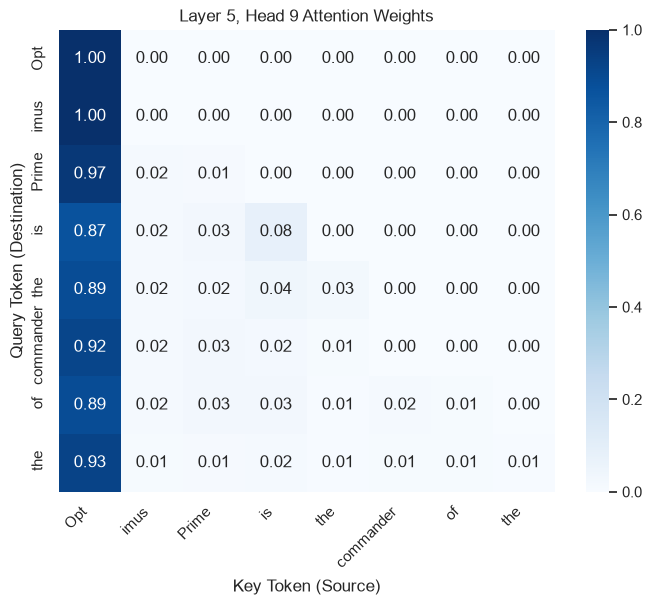

Model Response:
Optimus Prime is the commander of the Legion, a non-human race that has been fighting for millennia. The Emperor's forces have reclaimed


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import circuitsvis as cv
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# ==============================================================================
# CHAPTER 1: ENVIRONMENT SETUP & MODEL INITIALIZATION
# ==============================================================================
# We establish our hardware acceleration device (Nvidia GPU via PyTorch).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# We use OpenAI's base GPT-2 as our model as it easier to interpet than future or larger models

model_id = "gpt2" 

# Initialize the tokenizer 
tokenizer = GPT2Tokenizer.from_pretrained(model_id) 

# We configure `attn_implementation="eager"` to expose internal attention weights.
# Normally, AI models hide how words connect to save memory and run faster. 
# "Eager" mode forces it to show us how the words connect to make it easier to analyze.

model = GPT2LMHeadModel.from_pretrained(model_id, attn_implementation="eager").to(device)
model.eval() # Set model to evaluation model

# ==============================================================================
# CHAPTER 2: FORWARD PASS & ATTENTION TENSOR EXTRACTION
# ==============================================================================

# We send a test prompt to examine how the model processes queries.

prompt = "Who is Optimus Prime?"

# Convert prompt text into token IDs and push them to the GPU tensor pipeline.
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# Decode individual token strings
tokens = [tokenizer.decode([t]) for t in inputs["input_ids"][0]]

# This forces the transformer blocks to return the internal attention weight matrices instead of just logits.
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# We stack them into a single tensor of shape: [num_layers, batch_size, num_heads, q_pos, k_pos]
all_attentions = torch.stack(outputs.attentions)

print(f"Prompt tokens: {tokens}")
print(f"Attention tensor shape (Layers, Batch, Heads, Query, Key): {all_attentions.shape}")


# ==============================================================================
# CHAPTER 3: INTERACTIVE MULTI-HEAD INSPECTION (CIRCUITSVIS)
# ==============================================================================
# We use CircuitsVis to produce a visualization.  
# We look at layer 11 and view all of the induction heads

display(cv.attention.attention_patterns(
    tokens=tokens,
    attention=all_attentions[11, 0] # Layer 11, Batch 0, all heads
))

# ==============================================================================
# CHAPTER 4: MICRO-CIRCUIT ANALYSIS (SEABORN HEATMAP)
# ==============================================================================

# To understand the token-to-token relationships, we isolate a specific attention head 
# (Layer 5, Head 9)

matrix = all_attentions[5, 0, 9].detach().cpu().numpy()

plt.figure(figsize=(8, 6))
sns.heatmap(matrix, xticklabels=tokens, yticklabels=tokens, annot=True, fmt=".2f", cmap="Blues")
plt.title("Detailed Circuit Analysis: Layer 5, Head 9 Attention Weights")
plt.xlabel("Key Token (Source - Where information is pulled FROM)")
plt.ylabel("Query Token (Destination - Where information is sent TO)")
plt.xticks(rotation=45, ha="right")
plt.show()

# ==============================================================================
# CHAPTER 5: BEHAVIORAL VERIFICATION & GENERATION
# ==============================================================================

# Finally, we test how the model behaves at the output layer by generating a completion. 

generation_inputs = tokenizer(prompt, return_tensors="pt")
input_ids = generation_inputs["input_ids"].to(device)

with torch.no_grad():
    output_ids = model.generate(
        input_ids,
        max_new_tokens=20,
        do_sample=True,          # Enable sampling for varied completions
        temperature=0.7,         # Control generation randomness
        repetition_penalty=1.2,  # Discourage repetitive loops
        pad_token_id=tokenizer.eos_token_id
    )

response_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(f"\nModel Behavioral Response:\n{response_text}")


Residual Stream Layer 0 vs Layer  3 Cosine Similarity: 0.8997
Residual Stream Layer 0 vs Layer  6 Cosine Similarity: 0.8022
Residual Stream Layer 0 vs Layer  9 Cosine Similarity: 0.6591
Residual Stream Layer 0 vs Layer 11 Cosine Similarity: 0.4334


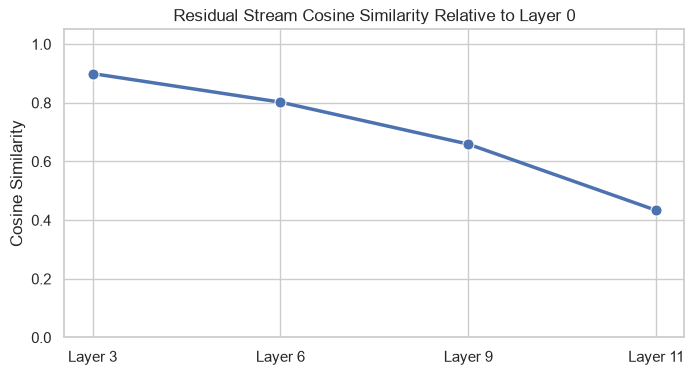

In [2]:
# 1. Initialize caches for residual stream, attention, and MLP
cache = {"resid": {}, "attn": {}, "mlp": {}}

def register_traps():
    handles = []
    for idx, block in enumerate(model.transformer.h):
        handles.append(block.register_forward_hook(
            lambda m, i, o, l=idx: cache["resid"].update({l: (o[0] if isinstance(o, tuple) else o).squeeze(0).detach()})
        ))
        handles.append(block.attn.register_forward_hook(
            lambda m, i, o, l=idx: cache["attn"].update({l: o[0].squeeze(0).detach()})
        ))
        handles.append(block.mlp.register_forward_hook(
            lambda m, i, o, l=idx: cache["mlp"].update({l: o.squeeze(0).detach()})
        ))
    return handles

# 2. Run forward pass to populate traps, then clean up hooks
handles = register_traps()
with torch.no_grad():
    _ = model(**inputs)
for h in handles:
    h.remove()

# 3. Cosine similarity evolution relative to Layer 0 (for the final token)
target_layers = [3, 6, 9, 11]
resid_sims = [F.cosine_similarity(cache["resid"][0][-1], cache["resid"][l][-1], dim=0).item() for l in target_layers]

for l, sim in zip(target_layers, resid_sims):
    print(f"Residual Stream Layer 0 vs Layer {l:2d} Cosine Similarity: {sim:.4f}")

# 4. Visualize Residual Stream progression
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))
sns.lineplot(x=[f"Layer {l}" for l in target_layers], y=resid_sims, marker="o", linewidth=2.5, markersize=8)
plt.title("Residual Stream Cosine Similarity Relative to Layer 0")
plt.ylabel("Cosine Similarity")
plt.ylim(0, 1.05)
plt.show()

In [3]:
def run_logit_lens(token_idx, label):
    print(f"\nLogit Lens progression for '{label}' (index {token_idx}):")
    for layer_idx in range(len(model.transformer.h)):
        h_state = cache["resid"][layer_idx][token_idx]
        logits = model.lm_head(model.transformer.ln_f(h_state))
        top_token = tokenizer.decode([logits.argmax().item()])
        print(f"  Layer {layer_idx:2d} -> Top Prediction: '{top_token}'")

# Trace index 0 ('Opt' -> 'ical') and final prediction position (after ' the')
run_logit_lens(0, tokens[0])
run_logit_lens(len(tokens) - 1, tokens[-1])


Logit Lens progression for 'Opt' (index 0):
  Layer  0 -> Top Prediction: 'ical'
  Layer  1 -> Top Prediction: ' the'
  Layer  2 -> Top Prediction: ','
  Layer  3 -> Top Prediction: ','
  Layer  4 -> Top Prediction: ','
  Layer  5 -> Top Prediction: ','
  Layer  6 -> Top Prediction: ','
  Layer  7 -> Top Prediction: ','
  Layer  8 -> Top Prediction: ','
  Layer  9 -> Top Prediction: ','
  Layer 10 -> Top Prediction: ','
  Layer 11 -> Top Prediction: '.'

Logit Lens progression for ' the' (index 7):
  Layer  0 -> Top Prediction: ' same'
  Layer  1 -> Top Prediction: ' same'
  Layer  2 -> Top Prediction: ' same'
  Layer  3 -> Top Prediction: ' same'
  Layer  4 -> Top Prediction: ' same'
  Layer  5 -> Top Prediction: ' same'
  Layer  6 -> Top Prediction: ' first'
  Layer  7 -> Top Prediction: ' first'
  Layer  8 -> Top Prediction: ' fleet'
  Layer  9 -> Top Prediction: ' USS'
  Layer 10 -> Top Prediction: ' USS'
  Layer 11 -> Top Prediction: ' Autob'


In [4]:
# --- A. ACTIVATION PATCHING ---
clean_inputs = tokenizer("Optimus Prime is the commander of the", return_tensors="pt").to(device)
corrupted_inputs = tokenizer("Megatron is the leader of the", return_tensors="pt").to(device)

# Capture clean Layer 9 residual state
clean_state = {}
h_clean = model.transformer.h[9].register_forward_hook(
    lambda m, i, o: clean_state.update({"val": (o[0] if isinstance(o, tuple) else o).detach().clone()})
)
with torch.no_grad():
    _ = model(**clean_inputs)
h_clean.remove()

# Patch Layer 9 during the corrupted run
def patch_hook(module, input, output):
    is_tuple = isinstance(output, tuple)
    tensor = output[0] if is_tuple else output
    tensor[:, -1, :] = clean_state["val"][:, -1, :]
    return (tensor,) + output[1:] if is_tuple else tensor

h_patch = model.transformer.h[9].register_forward_hook(patch_hook)
with torch.no_grad():
    patched_out = model(**corrupted_inputs)
h_patch.remove()

patched_pred = tokenizer.decode([patched_out.logits[0, -1, :].argmax().item()])
print(f"Corrupted prompt prediction after patching Layer 9: '{patched_pred}'")

# --- B. STEERING VECTORS ---
# Extract concept difference vector at Layer 9 (Optimus - Megatron)
pos_inputs = tokenizer(
    "Optimus Prime is the leader of the", return_tensors="pt"
).to(device)
base_inputs = tokenizer("Megatron is the leader of the", return_tensors="pt").to(device)
vecs = {}

for key, inp in [("pos", pos_inputs), ("base", base_inputs)]:
    h = model.transformer.h[9].register_forward_hook(
        lambda m, i, o, k=key: vecs.update({k: (o[0] if isinstance(o, tuple) else o)[0, -1, :].detach().clone()})
    )
    with torch.no_grad():
        _ = model(**inp)
    h.remove()

steering_vector = vecs["pos"] - vecs["base"]
alpha = 0.8

def steering_hook(module, input, output):
    is_tuple = isinstance(output, tuple)
    tensor = output[0] if is_tuple else output
    tensor[:, -1, :] += alpha * steering_vector
    return (tensor,) + output[1:] if is_tuple else tensor

test_ids = tokenizer("The giant alien robot transformed into a truck and said,", return_tensors="pt").to(device)
h_steer = model.transformer.h[9].register_forward_hook(steering_hook)
with torch.no_grad():
    gen_ids = model.generate(**test_ids, max_new_tokens=30, do_sample=True, temperature=0.7, repetition_penalty=1.2)
h_steer.remove()

print(
    "\nSteered Generation:"
)
print(tokenizer.decode(gen_ids[0], skip_special_tokens=True))

Corrupted prompt prediction after patching Layer 9: ' Autob'

Steered Generation:
The giant alien robot transformed into a truck and said, "I'm going to take care of this for you. I'll give it everything in return."
When he took his time getting dressed up on
